# 03 – Teden 5: kompleksnejše vizualizacije in primerjava z obstoječimi analizami

**Vsebina:**
1. Vizualizacije ene, dveh in treh spremenljivk na ravni občin.
2. Primerjava naših podatkov z uradnimi objavami statističnih uradov (BFS, ASTAT/Eurac).
3. Primerjava z znanstveno literaturo o vplivu snega in nadmorske višine na zimski turizem (Falk 2010, Gonseth 2013, Steiger in sod. 2019).

Nabor je isti kot v `02_osnovne_vizualizacije.ipynb`: hoteli, Južna Tirolska (ASTAT, kategorija `A`) in Švica (BFS), 2013–2025, občine z vsaj 95 % opazovanih mesecev (brez let 2020–2021).
Za razliko od zvezka 02 tu ne gledamo le vsote čez vse visoke občine, ampak **vsako občino posebej**, kar omogoča povezavo z nadmorsko višino.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
ALT_MIN = 1000
YEARS = (2013, 2025)
COVID = [2020, 2021]
WINTER, SUMMER = [12, 1, 2, 3], [6, 7, 8, 9]

COLORS = {"IT": "#2a78d6", "CH": "#eb6834"}
LABELS = {"IT": "Italija (Južna Tirolska)", "CH": "Švica"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#9a9893", "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})

In [2]:
df = pd.read_csv(ROOT / "data/processed/tourism_monthly.csv", dtype={"muni_id": str}, parse_dates=["date"])
hot = df[(df["scope"] == "hotel") & df["year"].between(*YEARS)].copy()

normal = hot[~hot["year"].isin(COVID)]
coverage = normal.groupby(["country", "muni_id"])["overnights"].count() / normal["date"].nunique()
keep = coverage[coverage >= 0.95].index
hot = hot.set_index(["country", "muni_id"]).loc[keep].reset_index()
normal = hot[~hot["year"].isin(COVID)]

# one row per municipality: elevation, size, winter share of annual overnights (Dec-Mar)
muni = (normal.groupby(["country", "muni_id"])
              .agg(name=("muni_name", "first"), elev_m=("elev_m", "first"),
                   elev_ambiguous=("elev_ambiguous", "first"),
                   total=("overnights", "sum"), years=("year", "nunique")))
muni["annual"] = muni["total"] / muni["years"]
muni["winter_share"] = (normal[normal["month"].isin(WINTER)]
                        .groupby(["country", "muni_id"])["overnights"].sum() / muni["total"])
muni = muni.dropna(subset=["elev_m", "winter_share"]).reset_index()
muni["high"] = muni["elev_m"] >= ALT_MIN

# --- heatmap: monthly overnights of high municipalities vs. the 2013-2019 mean of the same month (section 3b)
high = hot[hot["elev_m"] >= ALT_MIN]
tot = high.groupby(["country", "year", "month"])["overnights"].sum(min_count=1).reset_index()
base = tot[tot["year"].between(2013, 2019)].groupby(["country", "month"])["overnights"].mean()
tot["dev"] = tot["overnights"] / tot.set_index(["country", "month"]).index.map(base) - 1

# --- comparison with official figures (section 4)
allh = df[df["scope"] == "hotel"]
ch = allh[allh["source"] == "BFS"]
st_all = df[(df["source"] == "ASTAT") & (df["scope"] == "all")]

def season_total(d, end_year):   # tourist winter season Nov(end_year-1) to Apr(end_year)
    m = ((d["year"] == end_year - 1) & (d["month"] >= 11)) | ((d["year"] == end_year) & (d["month"] <= 4))
    return d.loc[m, "overnights"].sum()

ch_year = ch.groupby("year")["overnights"].sum()
ch_high = ch[ch["elev_m"] >= ALT_MIN].groupby("year")["overnights"].sum()
st_year = st_all.groupby("year")["overnights"].sum()
ch_high_df = ch[ch["elev_m"] >= ALT_MIN]

rows = [
    ("CH 2020 vs 2019 (%)", -40.0, (ch_year[2020] / ch_year[2019] - 1) * 100,
     (ch_high[2020] / ch_high[2019] - 1) * 100),
    ("CH zima 2020/21 vs 2019/20 (%)", -26.4,
     (season_total(ch, 2021) / season_total(ch, 2020) - 1) * 100,
     (season_total(ch_high_df, 2021) / season_total(ch_high_df, 2020) - 1) * 100),
    ("CH 2024 vs 2023 (%)", 2.6, (ch_year[2024] / ch_year[2023] - 1) * 100,
     (ch_high[2024] / ch_high[2023] - 1) * 100),
    ("CH 2024, mio. prenočitev", 42.8, ch_year[2024] / 1e6, ch_high[2024] / 1e6),
    ("Južna Tirolska 2022, mio.", 34.4, st_year[2022] / 1e6, np.nan),
    ("Južna Tirolska 2023, mio.", 36.1, st_year[2023] / 1e6, np.nan),
]
check = pd.DataFrame(rows, columns=["kazalnik", "uradno", "naši podatki", f"naši, občine >= {ALT_MIN} m"])

# --- year-to-year volatility of winter and summer overnights by elevation band (section 5)
hot["season"] = np.where(hot["month"] == 12, hot["year"] + 1, hot["year"])
win = hot[hot["month"].isin(WINTER)].groupby(["country", "muni_id", "season"])["overnights"].sum(min_count=4)
summ = hot[hot["month"].isin(SUMMER)].groupby(["country", "muni_id", "year"])["overnights"].sum(min_count=4)

# seasons untouched by COVID (winter 2020 ended early, 2021 lost, 2022 still restricted in Italy)
OK_WINTER = [2014, 2015, 2016, 2017, 2018, 2019, 2023, 2024, 2025]
OK_SUMMER = [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2022, 2023, 2024, 2025]

def volatility(s, ok):
    s = s[s.index.get_level_values(2).isin(ok)]
    change = np.log(s).groupby(level=[0, 1]).diff()
    consecutive = [y for y in ok if y - 1 in ok]
    change = change[change.index.get_level_values(2).isin(consecutive)]
    return change.groupby(level=[0, 1]).std()

vol = pd.DataFrame({"winter": volatility(win, OK_WINTER), "summer": volatility(summ, OK_SUMMER)}).reset_index()
vol = vol.merge(muni[["country", "muni_id", "name", "elev_m"]], on=["country", "muni_id"]).dropna()
BANDS = [0, 600, 1000, 4000]
BAND_LABELS = ["< 600 m", "600–1000 m", "≥ 1000 m"]
vol["band"] = pd.cut(vol["elev_m"], BANDS, labels=BAND_LABELS, right=False)
table = vol.groupby(["country", "band"], observed=True).agg(
    n=("muni_id", "size"), winter=("winter", "median"), summer=("summer", "median"))

muni.groupby("country").agg(municipalities=("muni_id", "size"), high=("high", "sum"),
                            median_winter_share=("winter_share", "median")).round(3)

,municipalities,high,median_winter_share
country,,,
CH,171,40,0.261
IT,106,44,0.259


## 1. Ena spremenljivka: porazdelitev zimskega deleža

Za vsako občino izračunamo **zimski delež** = prenočitve december–marec / vse prenočitve v letu (povprečje let brez covida).
Pri enakomernem obisku bi bil delež 4/12 = 33 %. Histogram pokaže, koliko občin je pretežno zimskih in koliko poletnih.

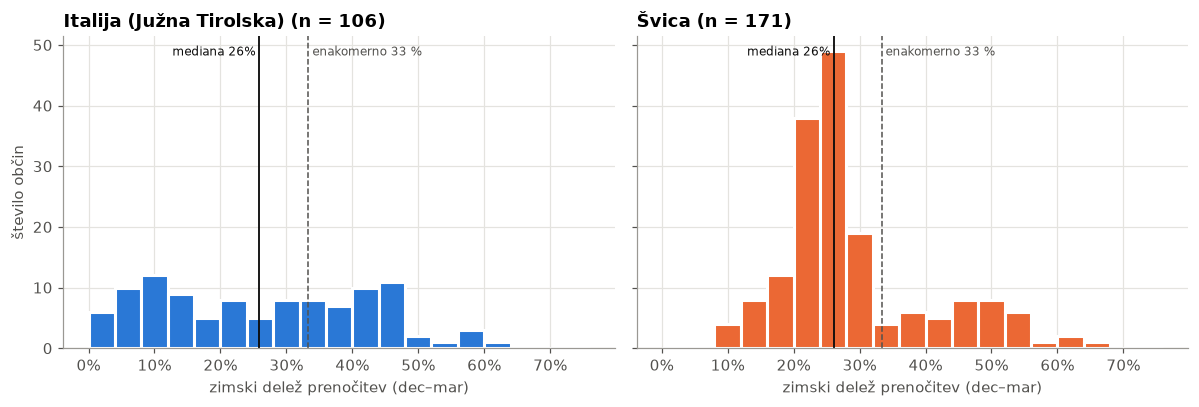

In [3]:
bins = np.arange(0, 0.80, 0.04)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, c in zip(axes, ["IT", "CH"]):
    m = muni[muni["country"] == c]
    ax.hist(m["winter_share"], bins=bins, color=COLORS[c], edgecolor="white", linewidth=2)
    ax.axvline(1 / 3, color=MUTED, lw=1, ls="--")
    ax.axvline(m["winter_share"].median(), color=INK, lw=1.2)
    ax.text(1 / 3, 0.97, " enakomerno 33 %", transform=ax.get_xaxis_transform(), color=MUTED, fontsize=8, va="top")
    ax.text(m["winter_share"].median(), 0.97, transform=ax.get_xaxis_transform(), s=
            f"mediana {m['winter_share'].median():.0%} ", color=INK, fontsize=8, va="top", ha="right")
    ax.set_title(f"{LABELS[c]} (n = {len(m)})", loc="left")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("zimski delež prenočitev (dec–mar)")
axes[0].set_ylabel("število občin")
plt.tight_layout()
plt.show()

In [4]:
# the most winter-dependent and the most summer-oriented municipalities
cols = ["country", "name", "elev_m", "winter_share", "annual"]
top = muni.sort_values("winter_share", ascending=False)
pd.concat([top.groupby("country").head(5), top.groupby("country").tail(3)])[cols].sort_values(
    ["country", "winter_share"], ascending=[True, False]).round({"winter_share": 3, "annual": 0})

,country,name,elev_m,winter_share,annual
85,CH,Arosa,1775.0,0.674,393566.0
74,CH,Samnaun,1846.0,0.633,160676.0
68,CH,Laax,1016.0,0.607,210046.0
55,CH,Flums,456.0,0.584,25170.0
64,CH,Vaz/Obervaz,1300.0,0.541,237288.0
162,CH,Innertkirchen,625.0,0.095,23216.0
99,CH,Ascona,199.0,0.094,403732.0
158,CH,Clos du Doubs,440.0,0.083,9874.0
193,IT,Corvara in Badia,1568.0,0.605,833921.0
211,IT,Marebbe,1186.0,0.577,431627.0


**Opažanja:**
- Mediana zimskega deleža je v obeh državah okoli 26 %, torej je tipična občina iz nabora bolj poletna kot zimska.
- Porazdelitev v Južni Tirolski je široka in skoraj dvovrha: veliko občin z manj kot 15 % (npr. Tirolo/Dorf Tirol, Rifiano ob Meranu, Vadena) in druga skupina okoli 40–50 % (dolomitske doline). Tam se ločita dve vrsti turizma: poletni okoli Merana in Bocna ter zimski v Dolomitih.
- Švica je zgoščena okoli 20–30 %, ker je v naboru veliko mest in jezerskih krajev (Zürich, Basel, Luzern), kjer je obisk razporejen čez vse leto. Izrazito zimske občine (nad 45 %) so »rep« porazdelitve: Arosa, Samnaun, Laax, Vaz/Obervaz (Lenzerheide).
- Najbolj zimske občine dosežejo 60–67 % (Arosa 67 %, Corvara 61 %), kar pomeni, da v štirih mesecih ustvarijo dve tretjini letnih prenočitev.

## 2. Dve spremenljivki: nadmorska višina in zimski delež

Vsaka točka je občina. Pričakujemo, da imajo višje ležeče občine (bližje smučiščem) večji zimski delež.
Pri Švici so prazni krogi občine z dvoumno nadmorsko višino v Wikidata (razpon nad 100 m), kjer je višina manj zanesljiva.
Rangovno korelacijo (Spearman) izračunamo s pandas.

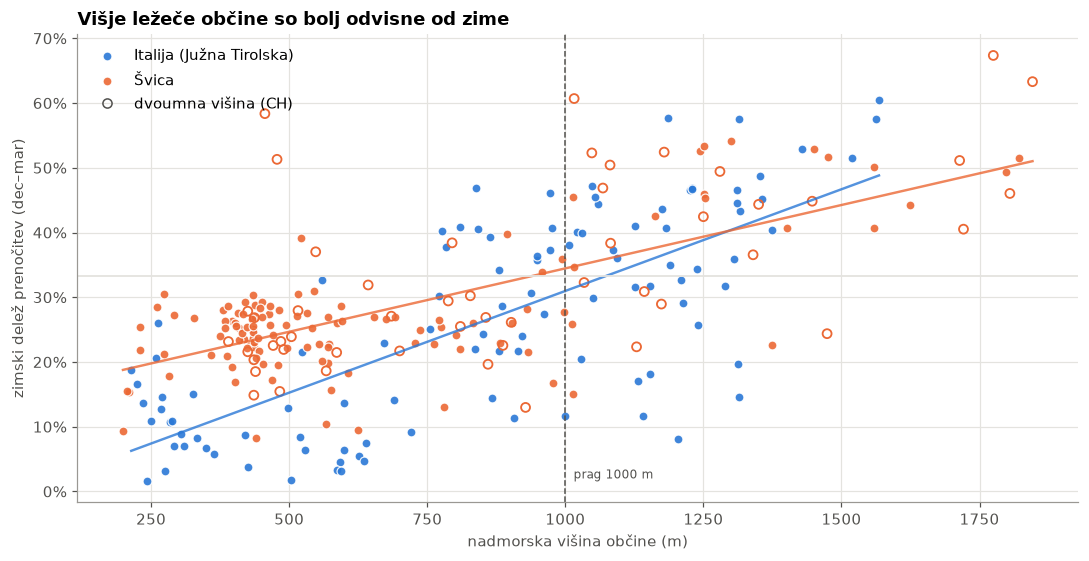

IT: Spearman rho = 0.71 (unambiguous elevation only: 0.71), slope = 3.1 percentage points per 100 m
CH: Spearman rho = 0.49 (unambiguous elevation only: 0.37), slope = 2.0 percentage points per 100 m


In [5]:
fig, ax = plt.subplots(figsize=(10, 5.2))
for c in ["IT", "CH"]:
    m = muni[muni["country"] == c]
    sure, amb = m[~m["elev_ambiguous"].astype(bool)], m[m["elev_ambiguous"].astype(bool)]
    ax.scatter(sure["elev_m"], sure["winter_share"], s=34, color=COLORS[c],
               edgecolor="white", linewidth=0.8, alpha=0.9, label=LABELS[c])
    ax.scatter(amb["elev_m"], amb["winter_share"], s=34, facecolor="none",
               edgecolor=COLORS[c], linewidth=1.2)
    # least-squares line to show the direction of the relation
    k, b = np.polyfit(m["elev_m"], m["winter_share"], 1)
    xs = np.array([m["elev_m"].min(), m["elev_m"].max()])
    ax.plot(xs, k * xs + b, color=COLORS[c], lw=1.6, alpha=0.8)

ax.axvline(ALT_MIN, color=MUTED, lw=1, ls="--")
ax.text(ALT_MIN + 15, 0.02, f"prag {ALT_MIN} m", color=MUTED, fontsize=8)
ax.axhline(1 / 3, color=GRID, lw=1.2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("nadmorska višina občine (m)")
ax.set_ylabel("zimski delež prenočitev (dec–mar)")
ax.set_title("Višje ležeče občine so bolj odvisne od zime", loc="left")
handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([], [], marker="o", ls="", markerfacecolor="none", markeredgecolor=MUTED))
labels.append("dvoumna višina (CH)")
ax.legend(handles, labels, frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

for c in ["IT", "CH"]:
    m = muni[muni["country"] == c]
    rho = m["elev_m"].rank().corr(m["winter_share"].rank())
    rho_sure = m.loc[~m["elev_ambiguous"].astype(bool), ["elev_m", "winter_share"]].rank().corr().iloc[0, 1]
    k = np.polyfit(m["elev_m"], m["winter_share"], 1)[0]
    print(f"{c}: Spearman rho = {rho:.2f} (unambiguous elevation only: {rho_sure:.2f}), "
          f"slope = {k * 100 * 100:.1f} percentage points per 100 m")

**Opažanja:**
- Povezava je jasno pozitivna: v Južni Tirolski je Spearmanov koeficient 0,71, zimski delež naraste za približno 3 odstotne točke na vsakih 100 m višine. V Švici je povezava šibkejša (0,49; slabi 2 o. t. na 100 m).
- Če v Švici upoštevamo le občine z nedvoumno višino, koeficient pade na 0,37, kar kaže, da je švicarska višina iz Wikidata res nezanesljiva (`PLAN.md`, korak 1) in jo bo treba popraviti.
- Prag 1000 m dobro loči skupini: pod njim je zimski delež skoraj vedno pod 40 %, nad njim pa večinoma nad 30 %. Izjeme so nizke občine s smučiščem nad naseljem (npr. Flums, 456 m, 58 %) in visoke občine brez večjega smučišča.
- Višina naselja je torej dober, a ne popoln približek za »smučarsko občino«; natančnejši bi bil seznam smučišč ali višina najvišje točke.

## 3. Tri spremenljivke

### 3a. Višina, zimski delež in velikost občine

Isti razsevni diagram, le da velikost kroga pomeni povprečno letno število hotelskih prenočitev. Tako vidimo, ali so zimske občine tudi turistično največje (npr. Zermatt, St. Moritz, Val Gardena).

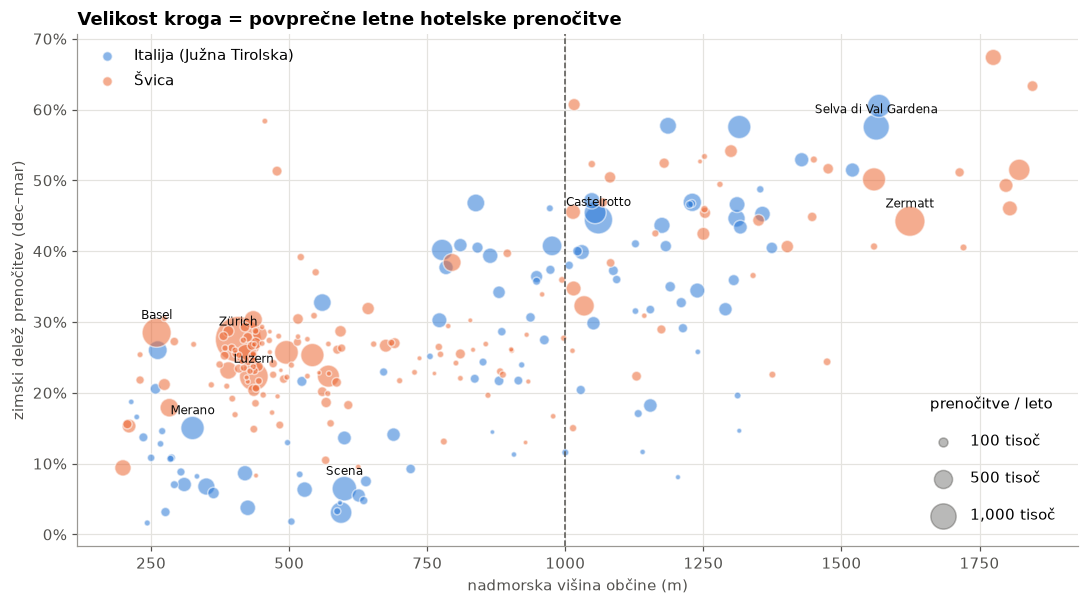

In [6]:
fig, ax = plt.subplots(figsize=(10, 5.6))
size = lambda v: 8 + v / muni["annual"].max() * 900
for c in ["IT", "CH"]:
    m = muni[muni["country"] == c].sort_values("annual", ascending=False)
    ax.scatter(m["elev_m"], m["winter_share"], s=size(m["annual"]), color=COLORS[c],
               alpha=0.55, edgecolor="white", linewidth=1, label=LABELS[c])
    for _, r in m.head(4).iterrows():   # label the four largest per country
        ax.annotate(r["name"], (r["elev_m"], r["winter_share"]), xytext=(0, 9),
                    textcoords="offset points", ha="center", fontsize=8, color=INK)

ax.axvline(ALT_MIN, color=MUTED, lw=1, ls="--")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("nadmorska višina občine (m)")
ax.set_ylabel("zimski delež prenočitev (dec–mar)")
ax.set_title("Velikost kroga = povprečne letne hotelske prenočitve", loc="left")
ref = [100_000, 500_000, 1_000_000]
handles = [plt.scatter([], [], s=size(v), color=MUTED, alpha=0.4) for v in ref]
leg1 = ax.legend(handles, [f"{v / 1e3:,.0f} tisoč" for v in ref], title="prenočitve / leto",
                 frameon=False, loc="lower right", labelspacing=1.4, borderpad=1)
ax.add_artist(leg1)
leg2 = ax.legend(frameon=False, loc="upper left")
for h in leg2.legend_handles:
    h.set_sizes([40])
plt.tight_layout()
plt.show()

**Opažanja:**
- Največje zimske destinacije so hkrati med največjimi turističnimi občinami sploh: Selva di Val Gardena, Corvara/Badia in Zermatt so zgoraj desno z velikimi krogi.
- Švicarske velike občine so večinoma mesta pod 600 m (Zürich, Basel, Luzern) z zimskim deležem 20–30 %; v Južni Tirolski sta veliki nizki občini Merano in Scena z zelo majhnim zimskim deležem (pod 15 %).
- Za primerjavo med državami zato ne smemo seštevati vseh občin: mestni turizem v Švici bi zabrisal zimsko sezonskost.

### 3b. Leto × mesec × odstopanje od običajne ravni

Toplotna karta za občine nad pragom: vrstica je leto, stolpec mesec, barva pa odstopanje prenočitev od povprečja **istega meseca** v letih 2013–2019 (v %).
Modra = več kot običajno, rdeča = manj. Tako se poleg covida pokažejo tudi slabše ali boljše posamezne sezone in dolgoročni trend.

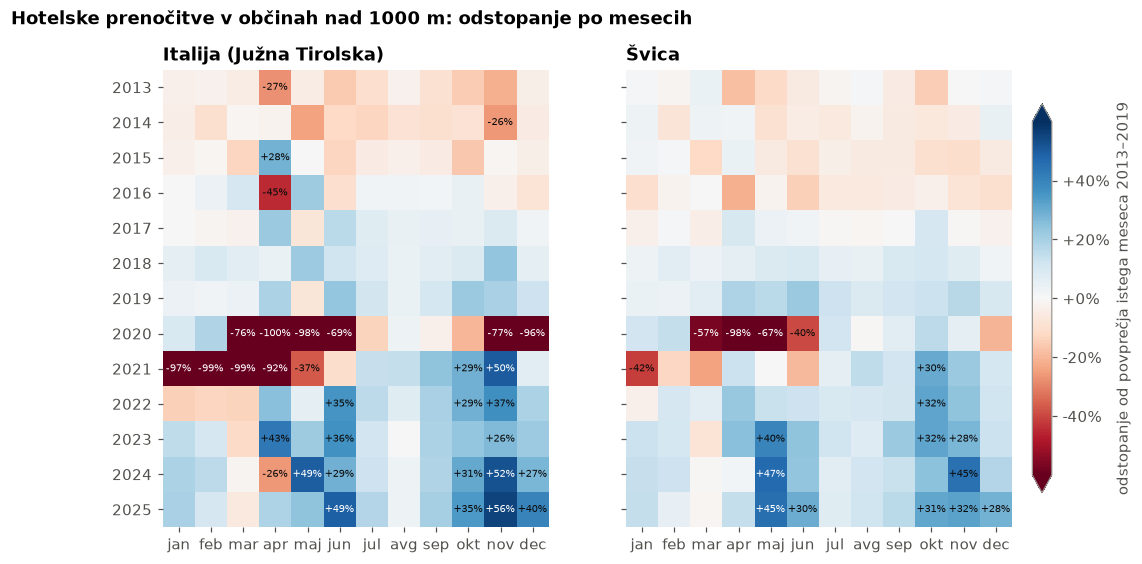

In [7]:
MONTHS = ["jan", "feb", "mar", "apr", "maj", "jun", "jul", "avg", "sep", "okt", "nov", "dec"]
norm = TwoSlopeNorm(vcenter=0, vmin=-0.6, vmax=0.6)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), sharey=True)
for ax, c in zip(axes, ["IT", "CH"]):
    grid = tot[tot["country"] == c].pivot(index="year", columns="month", values="dev")
    im = ax.imshow(grid, cmap="RdBu", norm=norm, aspect="auto")
    ax.set_xticks(range(12), MONTHS)
    ax.set_yticks(range(len(grid)), grid.index)
    ax.grid(False)
    for (i, j), v in np.ndenumerate(grid.to_numpy()):
        if np.isfinite(v) and abs(v) >= 0.25:   # label only the large deviations
            ax.text(j, i, f"{v:+.0%}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(v) > 0.45 else INK)
    ax.set_title(LABELS[c], loc="left")
    for s in ax.spines.values():
        s.set_visible(False)
cb = fig.colorbar(im, ax=axes, shrink=0.85, pad=0.02, extend="both")
cb.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
cb.set_label("odstopanje od povprečja istega meseca 2013–2019", color=MUTED)
fig.suptitle(f"Hotelske prenočitve v občinah nad {ALT_MIN} m: odstopanje po mesecih", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
plt.show()

In [8]:
# the strongest negative winter months outside the COVID period
w = tot[tot["month"].isin(WINTER) & ~tot["year"].isin(COVID) & ~((tot["year"] == 2022) & (tot["month"] <= 3))]
w.sort_values("dev").groupby("country").head(4)[["country", "year", "month", "dev"]].round(3)

,country,year,month,dev
182,IT,2015,3,-0.128
26,CH,2015,3,-0.121
278,IT,2023,3,-0.117
36,CH,2016,1,-0.101
169,IT,2014,2,-0.095
47,CH,2016,12,-0.094
122,CH,2023,3,-0.084
203,IT,2016,12,-0.081


**Opažanja:**
- **Covid** je najbolj izrazit: v Južni Tirolski od marca 2020 do aprila 2021 skoraj −100 %, v Švici pa izpad traja od marca do junija 2020, januarja 2021 pa le −42 %, ker so švicarska smučišča pozimi 2020/21 ostala odprta.
- **Velika noč:** april niha za ±30–45 % (2016 −45 %, 2024 −26 %, 2015 +28 %, 2023 +43 %). Velika noč je bila 27. 3. 2016 in 31. 3. 2024 (počitnice delno v marcu) ter 5. 4. 2015 in 9. 4. 2023 (počitnice v aprilu). Učinek datuma velike noči omenja tudi Falk (2010) za Avstrijo.
- **Daljše sezone po covidu:** od leta 2022 so meseci izven glavne sezone (maj, junij, oktober, november) 30–55 % nad ravnjo 2013–2019, glavna zimska meseca (januar, februar) pa le malo. Rast je torej predvsem v predsezoni in posezoni.
- Izven covida v visokih občinah **ni zime z izrazitim padcem** (najslabši zimski meseci so −10 do −13 %, npr. marec 2015 in marec 2023, oba z veliko nočjo v aprilu). To se ujema z ugotovitvijo, da so visoko ležeči kraji malo občutljivi na sneg (glej razdelek 5).

## 4. Primerjava z uradnimi objavami statističnih uradov

Najprej preverimo, ali naši (agregirani) podatki dajo enake številke, kot jih objavljajo uradne ustanove.

| Objava | Kaj navaja |
|---|---|
| BFS, sporočilo za javnost 19. 2. 2021 | Švica, hoteli: 2020 **23,7 mio.** prenočitev, **−40,0 %** glede na 2019 |
| BFS, sporočilo 8. 6. 2021 | zimska sezona 2020/21 (nov–apr): **9,4 mio.**, **−26,4 %** |
| BFS (povzeto po swissinfo.ch), 2025 | 2024 rekordnih **42,8 mio.** (2023: 41,8 mio.), **+2,6 %** |
| Eurac Research, Sustainable Tourism Observatory (STOST) | Južna Tirolska, vse nastanitve: 2022 **34,4 mio.**, 2023 **36,1 mio.**, nov rekord, nad ravnjo 2019 |

Pomembno: BFS navaja **vso Švico**, naš nabor pa le 186 večjih turističnih občin (`bfs_tourism_monthly`). Primerjamo zato predvsem **relativne spremembe**, absolutne vrednosti pa kot delež pokritosti.

In [9]:
print(f"BFS coverage: our 186 communes hold {ch_year[2024] / 42.8e6:.0%} of Swiss hotel overnights in 2024")
check.round(1)

BFS coverage: our 186 communes hold 80% of Swiss hotel overnights in 2024


,kazalnik,uradno,naši podatki,"naši, občine >= 1000 m"
0,CH 2020 vs 2019 (%),-40.0,-42.5,-19.7
1,CH zima 2020/21 vs 2019/20 (%),-26.4,-28.9,-8.4
2,CH 2024 vs 2023 (%),2.6,2.9,-0.1
3,"CH 2024, mio. prenočitev",42.8,34.3,9.6
4,"Južna Tirolska 2022, mio.",34.4,34.4,NaN
5,"Južna Tirolska 2023, mio.",36.1,36.1,NaN


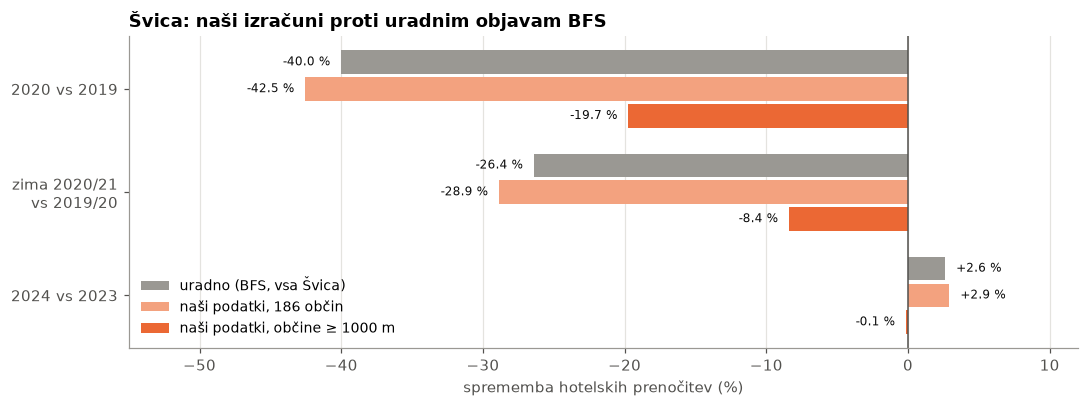

In [10]:
pct = check.iloc[:3].set_index("kazalnik")
labels = ["2020 vs 2019", "zima 2020/21\nvs 2019/20", "2024 vs 2023"]
series = [("uradno (BFS, vsa Švica)", "uradno", "#9a9893"),
          ("naši podatki, 186 občin", "naši podatki", "#f3a27f"),
          (f"naši podatki, občine ≥ {ALT_MIN} m", f"naši, občine >= {ALT_MIN} m", COLORS["CH"])]
fig, ax = plt.subplots(figsize=(10, 3.8))
y = np.arange(len(labels))
h = 0.26
for i, (lab, col, color) in enumerate(series):
    vals = pct[col].to_numpy()
    ax.barh(y + (i - 1) * h, vals, height=h - 0.03, color=color, label=lab)
    for yy, v in zip(y + (i - 1) * h, vals):
        ax.text(v + (0.8 if v >= 0 else -0.8), yy, f"{v:+.1f} %", va="center",
                ha="left" if v >= 0 else "right", fontsize=8, color=INK)
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.set_xlim(-55, 12)
ax.set_xlabel("sprememba hotelskih prenočitev (%)")
ax.set_title("Švica: naši izračuni proti uradnim objavam BFS", loc="left")
ax.legend(frameon=False, loc="lower left", fontsize=9)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Opažanja:**
- Naš nabor 186 švicarskih občin pokriva približno 80 % vseh švicarskih hotelskih prenočitev (34,3 od 42,8 mio. v letu 2024).
- Relativne spremembe se z uradnimi ujemajo na 0,3–2,5 odstotne točke: 2020 −42,5 % (BFS −40,0 %), zima 2020/21 −28,9 % (BFS −26,4 %), 2024 +2,9 % (BFS +2,6 %). Naš nabor je pri covidu nekoliko bolj negativen, verjetno ker vsebuje razmeroma več mest, kjer so manjkali tuji gosti.
- Za Južno Tirolsko se naše vsote (ASTAT, vse nastanitve) z vrednostmi, ki jih objavlja Eurac (34,4 in 36,1 mio.), ujemajo na 0,1 mio., kar je pričakovano, saj gre za isti vir.
- **Nova ugotovitev za smučarske občine:** občine nad 1000 m so leta 2020 izgubile le 20 % prenočitev in pozimi 2020/21 le 8 %, celotna Švica pa 40 % in 26 %. BFS navaja, da so tuji gosti pozimi 2020/21 upadli za 70 %, domači pa narasli za 16,5 %; domači gostje so se torej preselili v gore. Leta 2024 pa visoke občine niso več rasle (−0,1 %), rast je bila drugje.

## 5. Primerjava z znanstveno literaturo: sneg, nadmorska višina in stabilnost zime

**Kaj pravi literatura:**

- **Falk (2010)**, *A dynamic panel data analysis of snow depth and winter tourism*, Tourism Management 31(6), 912–924. Panel 28 avstrijskih smučarskih krajev, sezone 1986/87–2005/06.
  Prenočitve so dolgoročno povezane z višino snežne odeje (elastičnost 0,10: 10 % več snega → okoli 1 % več prenočitev), **v visoko ležečih krajih pa prenočitve od snega niso odvisne**.
- **Gonseth (2013)**, *Impact of snow variability on the Swiss winter tourism economy*, Climatic Change 119(2), 307–320. 74 švicarskih smučišč, sezone 2005/06–2008/09.
  Več dni z dovolj snega pomeni več obiskov smučišč in več prenočitev; vpliv na obiske smučišč je nekoliko večji kot na prenočitve. Med nižje in višje ležečimi smučišči v isti regiji obstaja konkurenca (gostje se ob slabem snegu preselijo višje).
- **Steiger, Scott, Abegg, Pons in Aall (2019)**, *A critical review of climate change risk for ski tourism*, Current Issues in Tourism 22(11), 1343–1379. Pregled 119 študij iz 27 držav o tem, kako podnebne spremembe ogrožajo smučarski turizem.

**Naša hipoteza:** če nižje ležeče občine bolj trpijo v slabih snežnih zimah, morajo biti njihove zimske prenočitve **bolj nestanovitne** iz leta v leto kot v višje ležečih občinah, poletne pa ne.

**Mera:** za vsako občino izračunamo standardni odklon letne spremembe (logaritma) zimskih prenočitev (dec–mar) med zaporednimi sezonami, brez covida. Enako za poletje (jun–sep) kot kontrolo.
Logaritemska sprememba odstrani dolgoročno rast in velikost občine.

Omejitev: v projektu (še) nimamo podatkov o snegu (to je naloga člana 2), zato je test posreden: nestanovitnost lahko povzročajo tudi drugi dejavniki (cene, menjalni tečaj, velikonočni prazniki, odpiranje hotelov).

In [11]:
table.round(3)

n  winter  summer
country band                          
CH      < 600 m     96   0.114   0.094
        600–1000 m  35   0.125   0.093
        ≥ 1000 m    40   0.089   0.098
IT      < 600 m     30   0.275   0.066
        600–1000 m  32   0.116   0.052
        ≥ 1000 m    44   0.079   0.061

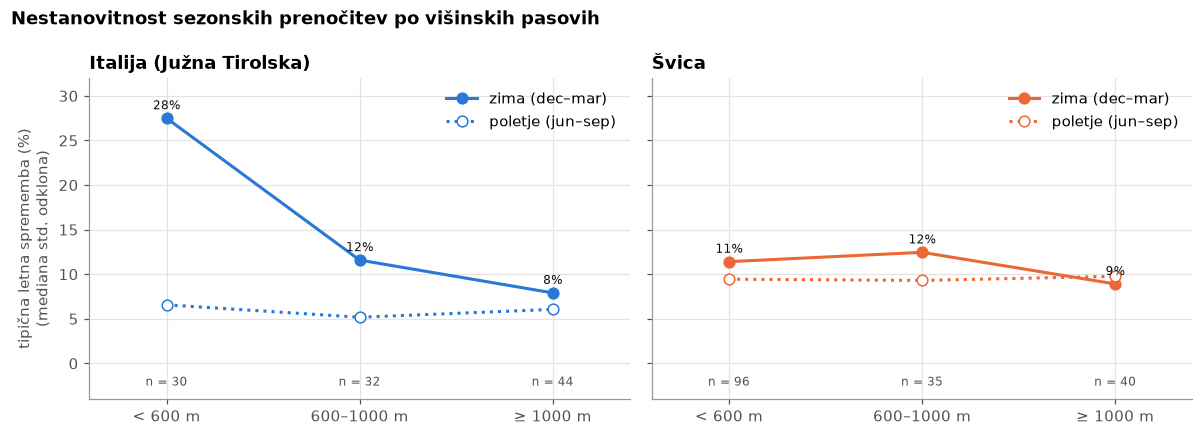

IT: Spearman(elevation, winter volatility) = -0.53, (elevation, summer volatility) = 0.03
CH: Spearman(elevation, winter volatility) = -0.07, (elevation, summer volatility) = 0.11


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, c in zip(axes, ["IT", "CH"]):
    t = table.loc[c]
    x = np.arange(len(t))
    ax.plot(x, t["winter"] * 100, color=COLORS[c], lw=2, marker="o", ms=7, label="zima (dec–mar)")
    ax.plot(x, t["summer"] * 100, color=COLORS[c], lw=2, marker="o", ms=7, ls=":",
            markerfacecolor="white", label="poletje (jun–sep)")
    for xx, (wv, sv, n) in enumerate(zip(t["winter"], t["summer"], t["n"])):
        ax.text(xx, wv * 100 + 1, f"{wv:.0%}", ha="center", fontsize=8, color=INK)
        ax.text(xx, -2.5, f"n = {n}", ha="center", fontsize=8, color=MUTED)
    ax.set_xticks(x, t.index)
    ax.set_xlim(-0.4, len(t) - 0.6)
    ax.set_title(LABELS[c], loc="left")
    ax.legend(frameon=False, loc="upper right")
axes[0].set_ylim(-4, 32)
axes[0].set_ylabel("tipična letna sprememba (%)\n(mediana std. odklona)")
fig.suptitle("Nestanovitnost sezonskih prenočitev po višinskih pasovih", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

for c in ["IT", "CH"]:
    v = vol[vol["country"] == c]
    rw = v["elev_m"].rank().corr(v["winter"].rank())
    rs = v["elev_m"].rank().corr(v["summer"].rank())
    print(f"{c}: Spearman(elevation, winter volatility) = {rw:.2f}, (elevation, summer volatility) = {rs:.2f}")

**Opažanja:**
- **Južna Tirolska potrdi literaturo:** zimske prenočitve so pod 600 m tipično nihale za 28 % na leto, med 600 in 1000 m za 12 %, nad 1000 m le za 8 %. Poletje je v vseh pasovih enako stabilno (5–7 %). Spearmanov koeficient med višino in zimsko nestanovitnostjo je −0,53, med višino in poletno pa 0,03. To je skladno s Falkom (2010), ki pri visoko ležečih krajih ne najde vpliva snega, in s pregledom Steigerja in sod. (2019), po katerem so nižje ležeči kraji najbolj izpostavljeni.
- Previdnost: v nizkih južnotirolskih občinah je zimskih prenočitev malo (veliko hotelov je pozimi zaprtih), zato že odprtje ali zaprtje enega hotela močno spremeni odstotek. Del nihanja zato ni posledica snega.
- **Švica literature ne potrdi jasno:** nestanovitnost je v vseh pasovih 9–12 % (koeficient −0,07). Razlog je verjetno, da so švicarske nizke občine pretežno mesta, kjer zimski obisk ni odvisen od snega, in da je švicarska višina iz Wikidata nezanesljiva. Gonseth (2013) je opazovala smučišča, ne vseh občin, zato rezultata nista neposredno primerljiva.
- Za neposreden test učinka snega potrebujemo vremenske podatke (član 2): korelacija zimskih prenočitev s številom dni s snežno odejo po višinskih pasovih bi bila naslednji korak.

## Povzetek

| Vprašanje | Naš rezultat | Obstoječa analiza | Ujemanje |
|---|---|---|---|
| Ali se naši podatki ujemajo z uradnimi? | CH −42,5 % (2020), −28,9 % (zima 20/21), +2,9 % (2024); JT 34,4 in 36,1 mio. | BFS −40,0 %, −26,4 %, +2,6 %; Eurac 34,4 in 36,1 mio. | da (razlika zaradi 186 občin namesto vse Švice) |
| So višje občine bolj zimske? | da, Spearman 0,71 (IT), 0,49 (CH) | izhodišče študij o smučarskem turizmu | da |
| So višje občine pozimi stabilnejše? | IT: nihanje 28 % → 12 % → 8 % z višino; CH: brez jasne razlike | Falk (2010): visoki kraji neodvisni od snega; Steiger in sod. (2019): nižji kraji najbolj ogroženi | IT da, CH ne (mestni turizem, slaba višina) |
| Kako je covid vplival na gore? | visoke CH občine izgubile le 8 % zime 2020/21 (vsa CH 26 %) | BFS: tuji gosti −70 %, domači +16,5 % | da, domači gostje so šli v gore |
| Kaj premika posamezne mesece? | april niha ±30–45 % glede na datum velike noči | Falk (2010): učinek datuma velike noči | da |

**Viri:**
- BFS (2021). *Record drop in overnight hotel stays in Switzerland in 2020.* Sporočilo za javnost, 19. 2. 2021. https://www.admin.ch/gov/en/start/documentation/media-releases.msg-id-82373.html
- BFS (2021). Sporočilo za javnost o zimski sezoni 2020/21 v hotelih, 8. 6. 2021. https://www.bfs.admin.ch/asset/en/17604952
- swissinfo.ch (2025), povzetek objave BFS: *Swiss hotels record a record number of overnight stays in 2024.* https://www.swissinfo.ch/eng/various/swiss-hotels-record-a-record-number-of-overnight-stays-in-2024/88902039
- Eurac Research, Sustainable Tourism Observatory of South Tyrol (STOST). https://sustainabletourism.eurac.edu/?p=2446
- Falk, M. (2010). A dynamic panel data analysis of snow depth and winter tourism. *Tourism Management*, 31(6), 912–924. https://doi.org/10.1016/j.tourman.2009.11.010
- Gonseth, C. (2013). Impact of snow variability on the Swiss winter tourism economy. *Climatic Change*, 119(2), 307–320. https://infoscience.epfl.ch/record/177595
- Steiger, R., Scott, D., Abegg, B., Pons, M., & Aall, C. (2019). A critical review of climate change risk for ski tourism. *Current Issues in Tourism*, 22(11), 1343–1379. https://doi.org/10.1080/13683500.2017.1410110